# wCSET lambda2 tuning (INTRA cohort)

Sweeps wCSET's `lambda2` regularization parameter on the real intracranial
(INTRA) validation data used throughout `processing_intra.qmd`, using the
same connectome the manuscript actually uses: the atlas connectome fused
with a geometry fallback, then thresholded to a 0/1 adjacency
(`con = (con > 0).astype(float)`, matching `processing_intra.qmd`'s
`build_connectivity` exactly). Rebuilt here from scratch per subject (not
read from disk) - only its eigensystem is persisted, under
`derivatives/mindmap/sub-*/eig/sub-*_eig.npz` (loaded via
`atlas="multicon"` in `processing_intra.qmd`).

**sLORETA reference:** also swept over the same `lambda2` grid, as a
connectome-free baseline (`mne.minimum_norm.make_inverse_operator(depth=None,
fixed=True)` + `apply_inverse(..., method="sLORETA")`, matching
`solve_inverse.py`), for direct visual comparison against wCSET (solid vs
dashed in the plots below).

**Validation recipe** - matches `processing_intra.qmd`'s
`estimate_ieeg.py` / `evaluate_vieeg_fidelity.py` exactly, with one
deliberate change: **baseline = `(0, 0.5)` s** (narrower than that file's
`(0, 1.0)` s), used both for `normalize_evoked_by_baseline` and as
`find_spike_window`'s noise reference. `find_spike_window` computes the
Global Field Power (GFP), thresholds it at `threshold_sd=3.0` standard
deviations above its own baseline-window mean (default `gap_fill_ms=100`,
`min_duration_ms=20`), and returns the resulting continuous
`(tmin, tmax)` - both temporal and spatial correlation below are computed
only inside that GFP-detected window, not over the whole baseline+spike
epoch.

For each (subject, lambda2):

1. Build `wCSET(depth=0.2, harm=5, harmonic_method="lowpass")` with the
   connectome's eigenvectors/eigenvalues (same non-swept params as
   `solve_inverse.py`).
2. `.solve(ave, lambda2)`.
3. Project to virtual iEEG (`compute_virtual_ieeg`, swept over
   `threshold` - see below; `conductivity` fixed at its default, also see
   below for why).
4. Normalize true/virtual iEEG by the baseline above, crop to the
   GFP-detected spike window.
5. `compute_evoked_correlation(mode="temporal"/"spatial",
   polarity_invariant=True)`, record the **mean** and **median** of each.

Grid: `lambda2 in [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0]`
(9 points, half-decade log spacing, extending the range already used in
`mindmap/tutorials/analysis/inverse/lambda2-tuning.ipynb`). Subjects: all 4
(`12, 34, 48, 50`), matching `processing_intra.qmd`.

**Projection-parameter sweep** - `compute_virtual_ieeg` (step 3 above)
has two more parameters. Neither touches the inverse solve: for a given
(subject, lambda2) the `stc` computed above is reused across every point
of this sweep, no extra inverse solves.

- `threshold in [0.0005, 0.001, 0.002, 0.003, 0.004, 0.005]` m
  (0.5/1/2/3/4/5 mm) - minimum source-electrode distance before the
  `1/distance`-type falloff is capped. `0.003` (3 mm) is the current
  default; per `index.qmd` this is framed as the assumed iEEG-MRI
  coregistration accuracy, not an average dipole spacing.
- `conductivity` - **not swept in the grid.** `compute_virtual_ieeg`'s
  denominator is `4*pi*conductivity*r^2`, with no other dependence on
  conductivity, so its output is exactly `v proportional to 1/conductivity`:
  a single global multiplicative scale factor applied to every channel
  and time point identically. `normalize_evoked_by_baseline` z-scores as
  `(x - baseline_mean) / baseline_std`, and both the mean and the std
  scale by that same constant - so it cancels out exactly, before
  `compute_evoked_correlation` (which is itself scale-invariant) even
  gets involved. Conductivity therefore cannot move
  `temporal_mean/median` or `spatial_mean/median` at all, by
  construction - it's not that the effect happens to be small, it's
  algebraically zero. Verified empirically (not just argued) in the
  "Sanity check" cell below, on one (subject, lambda2) combination,
  comparing `conductivity=0.25` (the tuned default) against
  `conductivity=0.3` (this project's actual BEM forward brain
  conductivity, `processing_intra.qmd`'s `conductivity = [0.3, 0.006,
  0.3]`) - if that assertion ever fails, something about this reasoning
  (or the underlying function) has changed and the grid below should
  sweep conductivity too.

The `plot_tuning` figures show the lambda2 comparison at the baseline
threshold (3mm). The `plot_projection_sensitivity` figure shows how
sensitive the (wCSET-only) correlations are to threshold, with lambda2
still on the x-axis and subjects averaged out.


In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import mne
import mindmap as mm
from scripts.data_manager import IntraManager

dm = IntraManager("processing/intra.config.yml")
SUBJECTS = ["12", "34", "48", "50"]
LAMBDA2_VALUES = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0]
BASELINE = (0.0, 0.5)

# compute_virtual_ieeg projection params - don't affect the inverse solve,
# only how source estimates get mapped onto iEEG channels.
# conductivity is only spot-checked below (see "Sanity check" cell) - it's
# a pure global scale factor on compute_virtual_ieeg's output, which
# baseline normalization + correlation-based scoring are both invariant
# to, so it can't move any result in this notebook and isn't swept in the
# main grid.
CONDUCTIVITY_VALUES = [0.25, 0.3]  # S/m: 0.25 = tuned default, 0.3 = this project's BEM forward brain conductivity (untuned)
BASELINE_CONDUCTIVITY = 0.25
THRESHOLD_VALUES = [0.0005, 0.001, 0.002, 0.003, 0.004, 0.005]  # m: minimum source-electrode distance, 0.5/1/2/3/4/5 mm (3 mm = current default)
BASELINE_THRESHOLD = 0.003

OUT_DIR = Path("./results/intra/lambda2_tuning")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# --- atlas reference (shared across subjects, mirrors connectivity.py) ---
probcon = dm.load_ref("REF_CON")
consistency = np.nan_to_num(probcon["matrices"]["consistency"][:, :])
length = np.nan_to_num(probcon["matrices"]["length"][:, :])
number = np.nan_to_num(probcon["matrices"]["numbStlines"][:, :])
atlas_mask = np.bitwise_and(consistency > 65, length > 0)
atlas_mask = np.bitwise_and(atlas_mask, number > 0)
ATLAS_WEIGHTS = length * atlas_mask  # weight = avg fiber lengths


## 1. Build connectome eigensystem (binarized, matches `processing_intra.qmd`)

In [2]:
def build_eig(sub):
    """Same atlas+geometry fuse + binarize recipe as processing_intra.qmd's
    build_connectivity - the manuscript's only connectome variant."""
    src = dm.load(sub, "fwd")["src"]
    parc = dm.load(sub, "dseg", segmentation="multiconn2022", scale="4")
    ras2tkras = dm.load(sub, "ras2tkras")

    con_atlas = mm.analysis.connectivity.connectome_from_atlas(
        src, parc, ATLAS_WEIGHTS, ras2tkras, sparsity=0.14, deterministic=True,
    )
    con_geom = mm.analysis.connectivity.connectome_from_geometry(
        src, maximum_dist=22, maximum_neigh=35, weights=True,
    )

    con = con_atlas.copy()
    fill_idx = np.argwhere((con_geom > 0) & (con_atlas == 0))
    con[fill_idx[:, 0], fill_idx[:, 1]] = con_geom[fill_idx[:, 0], fill_idx[:, 1]]
    con = (con > 0).astype(float)

    inv_con = np.divide(1, con, out=np.zeros_like(con), where=con > 0)
    eigvec, eigval = mm.analysis.connectivity.compute_cst(inv_con)
    return {"vec": eigvec, "val": eigval}


t0 = time.time()
EIGS = {}
for sub in SUBJECTS:
    EIGS[sub] = build_eig(sub)
    print(f"sub-{sub}: eig built ({time.time() - t0:.1f}s elapsed)")
print(f"Total eig setup time: {time.time() - t0:.1f}s")


sub-12: eig built (21.5s elapsed)


sub-34: eig built (43.2s elapsed)


sub-48: eig built (73.5s elapsed)


sub-50: eig built (96.7s elapsed)
Total eig setup time: 96.7s


## 2. Grid search

In [3]:
def load_subject_data(sub):
    fwd = dm.load(sub, "fwd")
    ave = dm.load(sub, "ave", task="spk")
    ncov = dm.load(sub, "cov", task="spk")
    iave = dm.load(sub, "i-ave", task="spk")

    iave_norm = mm.analysis.eeg.normalize_evoked_by_baseline(iave, baseline=BASELINE)
    tmin, tmax = mm.analysis.eeg.find_spike_window(iave, baseline=BASELINE)
    iave_win = iave_norm.copy().crop(tmin, tmax)

    return {
        "fwd": fwd, "ave": ave, "ncov": ncov, "iave": iave,
        "tmin": tmin, "tmax": tmax, "iave_win": iave_win,
    }


def score(iave_win, v, baseline, tmin, tmax):
    v_norm = mm.analysis.eeg.normalize_evoked_by_baseline(v, baseline=baseline)
    v_win = v_norm.copy().crop(tmin, tmax)

    corr_temporal = mm.analysis.eeg.compute_evoked_correlation(
        iave_win, v_win, mode="temporal", polarity_invariant=True,
    )
    corr_spatial = mm.analysis.eeg.compute_evoked_correlation(
        iave_win, v_win, mode="spatial", polarity_invariant=True,
    )
    return {
        "temporal_mean": float(np.mean(corr_temporal)),
        "temporal_median": float(np.median(corr_temporal)),
        "spatial_mean": float(np.mean(corr_spatial)),
        "spatial_median": float(np.median(corr_spatial)),
    }


# --- Sanity check: is conductivity really a no-op for these metrics? ---
# compute_virtual_ieeg's denominator is 4*pi*conductivity*r^2 with no other
# conductivity dependence, so its output is v ~ 1/conductivity - a single
# global scale factor. normalize_evoked_by_baseline z-scores as
# (x - baseline_mean) / baseline_std, and both scale by that same constant,
# so it cancels out exactly before compute_evoked_correlation (itself
# scale-invariant) is even involved. Checked here on one (subject, lambda2)
# combination instead of burning the whole grid on a dimension proven to be
# a no-op.
_sub0, _lambda0 = SUBJECTS[0], LAMBDA2_VALUES[len(LAMBDA2_VALUES) // 2]
_data0 = load_subject_data(_sub0)
_inv0 = mm.analysis.inverse.wCSET(
    forward=_data0["fwd"], noise_cov=_data0["ncov"], depth=0.2,
    eigenvectors=EIGS[_sub0]["vec"], eigenvalues=EIGS[_sub0]["val"],
    harm=5, harmonic_method="lowpass",
)
_stc0 = _inv0.solve(_data0["ave"], _lambda0)
_scores_by_conductivity = {}
for _conductivity in CONDUCTIVITY_VALUES:
    _v0 = mm.analysis.eeg.compute_virtual_ieeg(
        _data0["fwd"]["src"], _stc0, _data0["iave"],
        conductivity=_conductivity, threshold=BASELINE_THRESHOLD,
    )
    _scores_by_conductivity[_conductivity] = score(
        _data0["iave_win"], _v0, BASELINE, _data0["tmin"], _data0["tmax"],
    )
print(f"sub-{_sub0}, lambda2={_lambda0}: scores by conductivity -> {_scores_by_conductivity}")
_s_a, _s_b = _scores_by_conductivity.values()
assert all(np.isclose(_s_a[k], _s_b[k]) for k in _s_a), (
    "conductivity changed a correlation metric - invariance assumption broken, "
    "sweep conductivity in the grid below before trusting these plots"
)
print("Confirmed: conductivity has no effect on temporal/spatial correlation - not swept in the grid below.")


rows = []
t0 = time.time()
n_total = len(SUBJECTS) * len(LAMBDA2_VALUES) * 2  # wcset + sLORETA
n_done = 0

for sub in SUBJECTS:
    data = load_subject_data(sub)
    src = data["fwd"]["src"]

    # --- wCSET ---
    for lambda2 in LAMBDA2_VALUES:
        inv = mm.analysis.inverse.wCSET(
            forward=data["fwd"], noise_cov=data["ncov"], depth=0.2,
            eigenvectors=EIGS[sub]["vec"], eigenvalues=EIGS[sub]["val"],
            harm=5, harmonic_method="lowpass",
        )
        stc = inv.solve(data["ave"], lambda2)
        for threshold in THRESHOLD_VALUES:
            v = mm.analysis.eeg.compute_virtual_ieeg(
                src, stc, data["iave"], conductivity=BASELINE_CONDUCTIVITY, threshold=threshold,
            )
            rows.append({
                "Subject": sub, "Method": "wcset", "lambda2": lambda2,
                "threshold_mm": threshold * 1000,
                **score(data["iave_win"], v, BASELINE, data["tmin"], data["tmax"]),
            })
        n_done += 1

    # --- sLORETA, connectome-free baseline ---
    sloreta_inv = mne.minimum_norm.make_inverse_operator(
        data["ave"].info, data["fwd"], data["ncov"], depth=None, fixed=True, verbose="warning",
    )
    for lambda2 in LAMBDA2_VALUES:
        stc = mne.minimum_norm.apply_inverse(
            data["ave"], sloreta_inv, lambda2, method="sLORETA", verbose="warning",
        )
        for threshold in THRESHOLD_VALUES:
            v = mm.analysis.eeg.compute_virtual_ieeg(
                src, stc, data["iave"], conductivity=BASELINE_CONDUCTIVITY, threshold=threshold,
            )
            rows.append({
                "Subject": sub, "Method": "sloreta", "lambda2": lambda2,
                "threshold_mm": threshold * 1000,
                **score(data["iave_win"], v, BASELINE, data["tmin"], data["tmax"]),
            })
        n_done += 1

    print(f"sub-{sub} done ({n_done}/{n_total} combinations, {time.time() - t0:.1f}s elapsed)")

results_df = pd.DataFrame(rows)
results_df.to_csv(OUT_DIR / "lambda2_tuning_results.csv", index=False)
print(f"Total grid search time: {time.time() - t0:.1f}s")
results_df.head()


sub-12, lambda2=0.1: scores by conductivity -> {0.25: {'temporal_mean': 0.2946043317216129, 'temporal_median': 0.27886575542896996, 'spatial_mean': 0.24176363397804287, 'spatial_median': 0.19854407707458052}, 0.3: {'temporal_mean': 0.29460433172161293, 'temporal_median': 0.27886575542897024, 'spatial_mean': 0.24176363397804282, 'spatial_median': 0.19854407707458066}}
Confirmed: conductivity has no effect on temporal/spatial correlation - not swept in the grid below.


sub-12 done (18/72 combinations, 105.2s elapsed)


sub-34 done (36/72 combinations, 264.0s elapsed)


sub-48 done (54/72 combinations, 580.1s elapsed)


sub-50 done (72/72 combinations, 778.9s elapsed)
Total grid search time: 778.9s


,Subject,Method,lambda2,threshold_mm,temporal_mean,temporal_median,spatial_mean,spatial_median
0,12,wcset,0.001,0.5,0.299587,0.283252,0.290440,0.254152
1,12,wcset,0.001,1.0,0.299099,0.264226,0.290542,0.253809
2,12,wcset,0.001,2.0,0.301199,0.310499,0.289612,0.250889
3,12,wcset,0.001,3.0,0.308492,0.314808,0.281619,0.244168
4,12,wcset,0.001,4.0,0.310867,0.314808,0.282150,0.245139


## 3. Plots

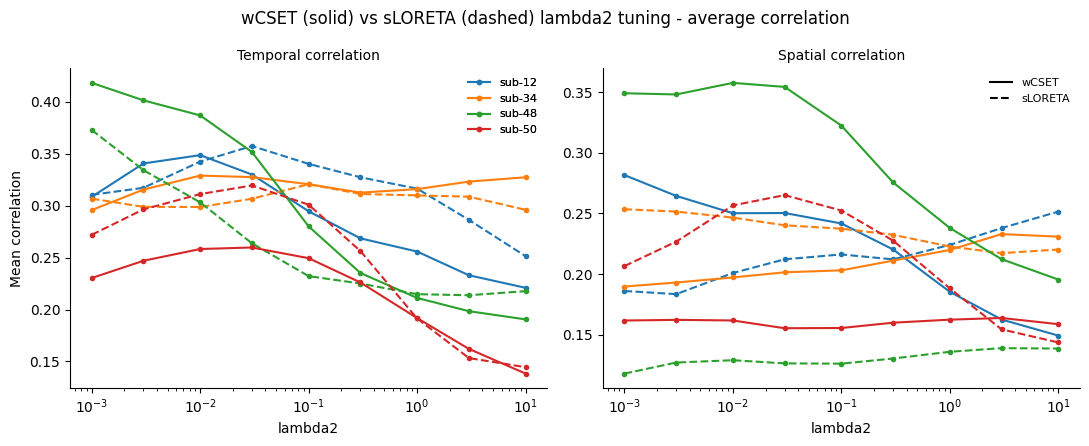

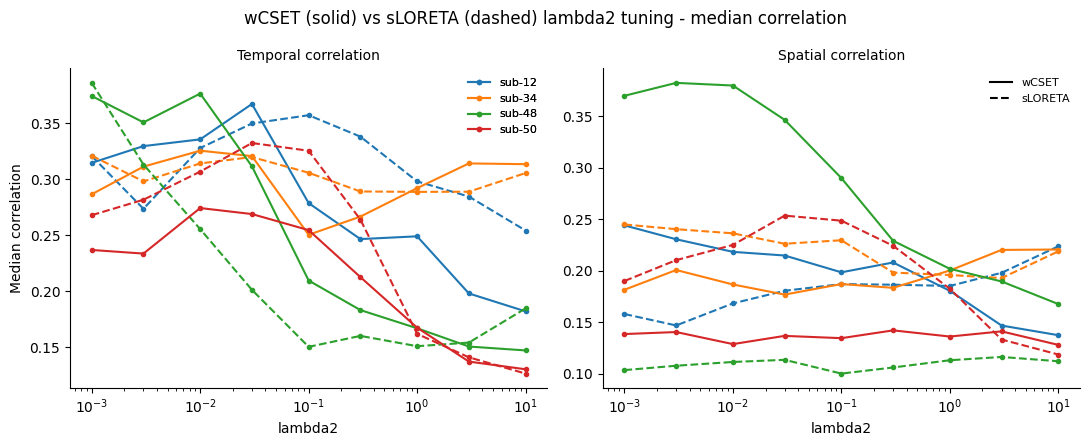

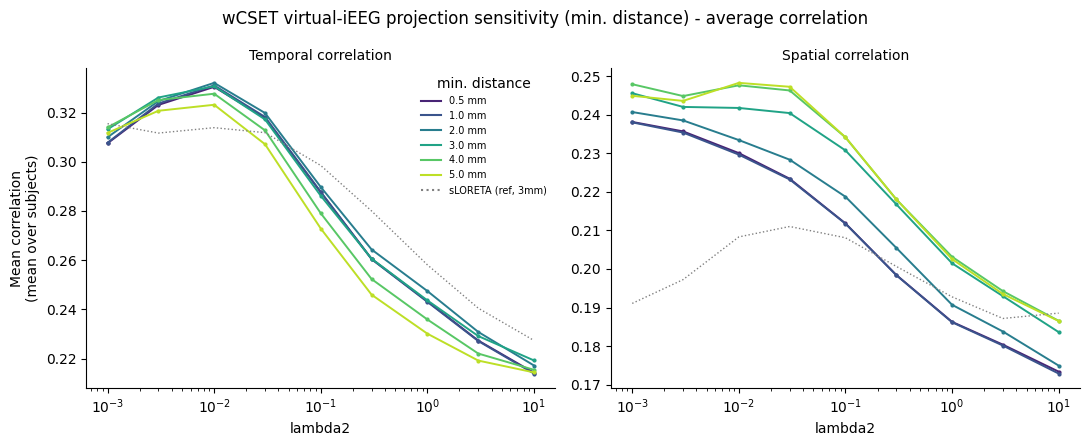

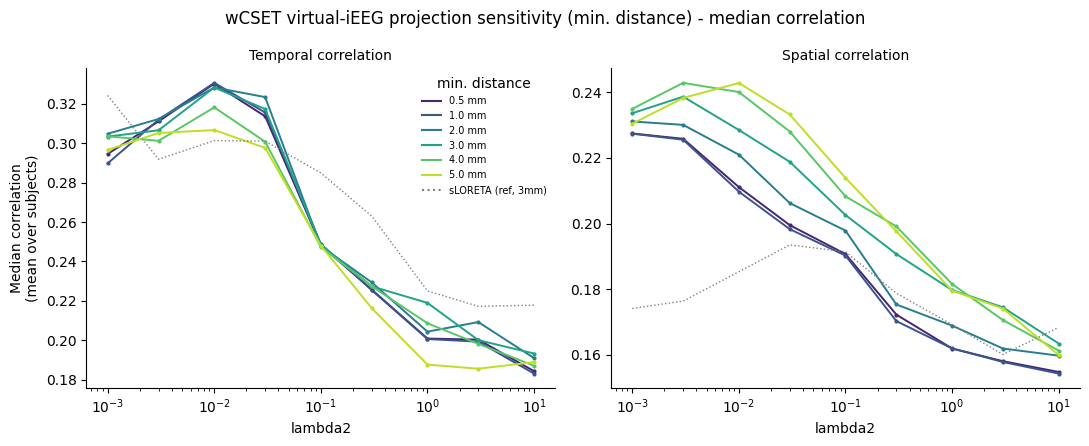

In [4]:
def plot_tuning(agg, title, fname):
    """wCSET vs sLORETA lambda2 comparison, at the baseline projection
    threshold (3mm) matching processing_intra.qmd."""
    metrics = [("temporal", "Temporal correlation"), ("spatial", "Spatial correlation")]
    colors = plt.cm.tab10.colors

    baseline_df = results_df[np.isclose(results_df["threshold_mm"], BASELINE_THRESHOLD * 1000)]

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True)
    for j, (metric, metric_label) in enumerate(metrics):
        ax = axes[j]
        col = f"{metric}_{agg}"
        for k, sub in enumerate(SUBJECTS):
            d_wcset = baseline_df[(baseline_df["Subject"] == sub) & (baseline_df["Method"] == "wcset")].sort_values("lambda2")
            ax.plot(d_wcset["lambda2"], d_wcset[col], marker="o", ms=3, color=colors[k], linestyle="-", label=f"sub-{sub}")

            d_sloreta = baseline_df[(baseline_df["Subject"] == sub) & (baseline_df["Method"] == "sloreta")].sort_values("lambda2")
            ax.plot(d_sloreta["lambda2"], d_sloreta[col], marker="o", ms=3, color=colors[k], linestyle="--")
        ax.set_xscale("log")
        ax.set_title(metric_label, fontsize=10)
        ax.spines[["top", "right"]].set_visible(False)
        ax.set_xlabel("lambda2")
        if j == 0:
            ax.set_ylabel(f"{agg.capitalize()} correlation")

    subject_legend = axes[0].legend(loc="best", fontsize=8, frameon=False)
    axes[0].add_artist(subject_legend)
    method_handles = [
        plt.Line2D([0], [0], color="black", linestyle="-", label="wCSET"),
        plt.Line2D([0], [0], color="black", linestyle="--", label="sLORETA"),
    ]
    axes[1].legend(handles=method_handles, loc="best", fontsize=8, frameon=False)

    fig.suptitle(title, fontsize=12)
    fig.tight_layout()
    fig.savefig(OUT_DIR / fname, dpi=150)
    plt.show()


plot_tuning("mean", "wCSET (solid) vs sLORETA (dashed) lambda2 tuning - average correlation", "lambda2_tuning_mean.png")
plot_tuning("median", "wCSET (solid) vs sLORETA (dashed) lambda2 tuning - median correlation", "lambda2_tuning_median.png")


def plot_projection_sensitivity(agg, title, fname):
    """How sensitive wCSET's correlation is to compute_virtual_ieeg's
    minimum-distance threshold, with lambda2 still on the x-axis and
    subjects averaged out. Conductivity isn't plotted: it's a pure global
    scale factor that this notebook's correlation-based scoring is
    invariant to (proven + verified in the "Sanity check" cell above), so
    it can't add another dimension worth showing."""
    metrics = [("temporal", "Temporal correlation"), ("spatial", "Spatial correlation")]
    threshold_colors = plt.cm.viridis(np.linspace(0.1, 0.9, len(THRESHOLD_VALUES)))

    wcset_df = results_df[results_df["Method"] == "wcset"]
    sloreta_df = results_df[
        (results_df["Method"] == "sloreta") & np.isclose(results_df["threshold_mm"], BASELINE_THRESHOLD * 1000)
    ]

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True)
    for j, (metric, metric_label) in enumerate(metrics):
        ax = axes[j]
        col = f"{metric}_{agg}"

        for t_idx, threshold in enumerate(THRESHOLD_VALUES):
            d = wcset_df[np.isclose(wcset_df["threshold_mm"], threshold * 1000)]
            d_mean = d.groupby("lambda2")[col].mean().reset_index().sort_values("lambda2")
            ax.plot(
                d_mean["lambda2"], d_mean[col],
                color=threshold_colors[t_idx], marker="o", ms=2, linewidth=1.4,
            )

        d_sloreta_mean = sloreta_df.groupby("lambda2")[col].mean().reset_index().sort_values("lambda2")
        ax.plot(d_sloreta_mean["lambda2"], d_sloreta_mean[col], color="gray", linestyle=":", linewidth=1)

        ax.set_xscale("log")
        ax.set_title(metric_label, fontsize=10)
        ax.spines[["top", "right"]].set_visible(False)
        ax.set_xlabel("lambda2")
        if j == 0:
            ax.set_ylabel(f"{agg.capitalize()} correlation\n(mean over subjects)")

    threshold_handles = [
        plt.Line2D([0], [0], color=threshold_colors[k], label=f"{t * 1000:.1f} mm")
        for k, t in enumerate(THRESHOLD_VALUES)
    ] + [plt.Line2D([0], [0], color="gray", linestyle=":", label="sLORETA (ref, 3mm)")]
    axes[0].legend(handles=threshold_handles, title="min. distance", loc="best", fontsize=7, frameon=False)

    fig.suptitle(title, fontsize=12)
    fig.tight_layout()
    fig.savefig(OUT_DIR / fname, dpi=150)
    plt.show()


plot_projection_sensitivity("mean", "wCSET virtual-iEEG projection sensitivity (min. distance) - average correlation", "projection_sensitivity_mean.png")
plot_projection_sensitivity("median", "wCSET virtual-iEEG projection sensitivity (min. distance) - median correlation", "projection_sensitivity_median.png")
